# Contract-defined billable value, invoices and credits

Reconcile at commitment grain before interpreting money. These are synthetic billing differences, not platform revenue, recognized revenue, realized savings or collections.

In [1]:
from pathlib import Path
import os, sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'tvads').exists(): ROOT=ROOT.parent
os.chdir(ROOT);sys.path.insert(0,str(ROOT))
from tvads.pipeline import current_output
OUT=current_output()
REPORTS=OUT/'reports'
summary=json.loads((REPORTS/'summary.json').read_text())
manifest=json.loads((OUT/'run_manifest.json').read_text())
fact=pd.read_parquet(OUT/'fact_commitments.parquet')
plt.rcParams.update({'figure.dpi':110,'axes.spines.top':False,'axes.spines.right':False})
print('Synthetic snapshot:',summary['as_of'])


Synthetic snapshot: 2026-07-15T00:00:00Z


In [2]:
pd.Series({k:summary[k] for k in ['expected_billable_cents','matched_net_invoiced_cents','overbilled_cents','underbilled_cents','unbilled_eligible_cents','billing_reconciliation_commitments','billing_reconciliation_rate']})

expected_billable_cents               2.928743e+08
matched_net_invoiced_cents            3.009171e+08
overbilled_cents                      2.524026e+07
underbilled_cents                     1.719745e+07
unbilled_eligible_cents               1.719745e+07
billing_reconciliation_commitments    1.704900e+04
billing_reconciliation_rate           8.153557e-01
dtype: float64

## The monetary bridge

Expected billable + overbilling - shortfalls equals matched net invoiced. Opposing discrepancies must remain separate when prioritizing investigations.

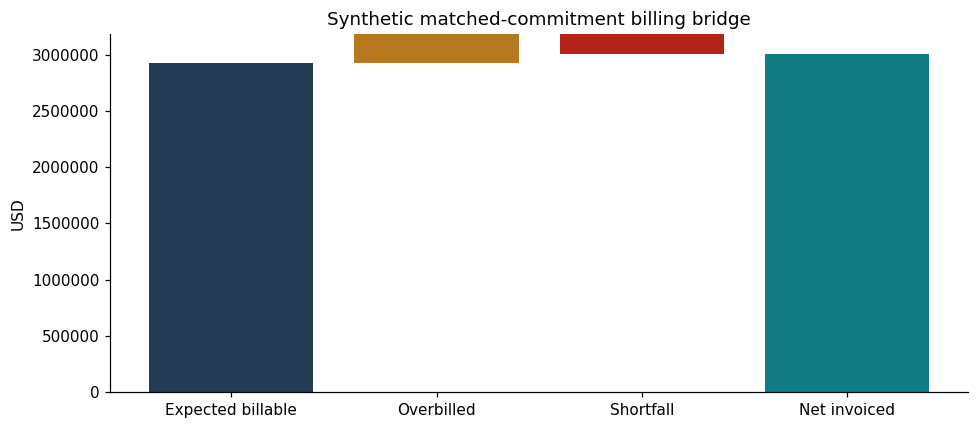

In [3]:
expected=summary['expected_billable_cents']/100
over=summary['overbilled_cents']/100
under=summary['underbilled_cents']/100
net=summary['matched_net_invoiced_cents']/100
assert abs(expected+over-under-net)<0.00001
fig,ax=plt.subplots(figsize=(9,4))
ax.bar(['Expected billable','Overbilled','Shortfall','Net invoiced'],[expected,over,-under,net],bottom=[0,expected,expected+over,0],color=['#243B55','#B7791F','#B42318','#117C83'])
ax.set_ylabel('USD');ax.set_title('Synthetic matched-commitment billing bridge');ax.ticklabel_format(axis='y',style='plain');plt.tight_layout();plt.show()

## Largest commitment differences

This is the correct monetary investigation grain. A commitment may have multiple exception labels, so summing amounts attached to those labels would duplicate exposure.

In [4]:
differences=fact[fact.billing_difference_cents.ne(0)].copy()
differences.sort_values('billing_difference_cents',key=abs,ascending=False)[['commitment_id','advertiser_id','campaign_id','expected_billable_cents','gross_invoiced_cents','credited_cents','net_invoiced_cents','billing_difference_cents']].head(15)

      commitment_id  ...  billing_difference_cents
16281      C0016282  ...                    -49614
13660      C0013661  ...                    -49614
12547      C0012548  ...                    -49614
3723       C0003724  ...                     49614
11735      C0011736  ...                     49614
9555       C0009556  ...                     49342
8611       C0008612  ...                    -49342
4050       C0004051  ...                     49342
16439      C0016440  ...                     49342
14660      C0014661  ...                     49342
5123       C0005124  ...                     49342
8848       C0008849  ...                    -49342
13054      C0013055  ...                    -49342
3015       C0003016  ...                    -49342
17902      C0017903  ...                    -49342

[15 rows x 8 columns]

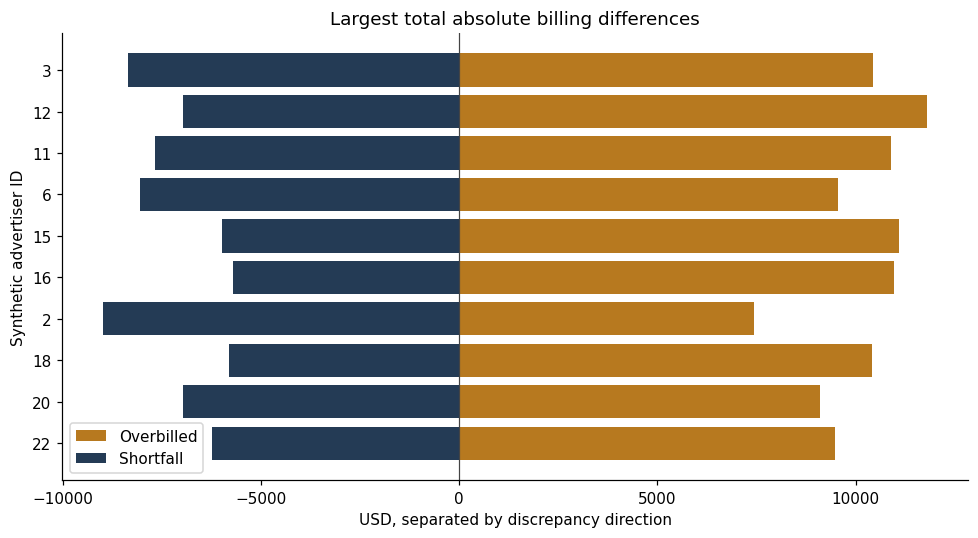

In [5]:
advertiser=pd.read_csv(REPORTS/'advertiser_billing.csv')
advertiser['absolute_investigation_cents']=advertiser.overbilled_cents+advertiser.underbilled_cents
priority=advertiser.nlargest(10,'absolute_investigation_cents').sort_values('absolute_investigation_cents')
fig,ax=plt.subplots(figsize=(9,5))
ax.barh(priority.advertiser_id.astype(str),priority.overbilled_cents/100,color='#B7791F',label='Overbilled')
ax.barh(priority.advertiser_id.astype(str),-priority.underbilled_cents/100,color='#243B55',label='Shortfall')
ax.axvline(0,color='#444444',linewidth=0.8);ax.set_xlabel('USD, separated by discrepancy direction');ax.set_ylabel('Synthetic advertiser ID');ax.legend();ax.set_title('Largest total absolute billing differences');plt.tight_layout();plt.show()

## Corrective credits and audit history

A wrong rate may already have a correcting credit. Keep the original error traceable without counting a second outstanding financial discrepancy.

In [6]:
ledger=pd.read_csv(OUT/'tableau_ready/fact_invoice_ledger.csv')
credited=ledger[ledger.credited_cents.gt(0)].merge(fact[['commitment_id','expected_billable_cents','billing_difference_cents']],on='commitment_id',validate='many_to_one')
credited[['invoice_line_id','commitment_id','amount_cents','credited_cents','net_invoiced_cents','expected_billable_cents','billing_difference_cents']].head(10)

  invoice_line_id  ... billing_difference_cents
0        I0000017  ...                        0
1        I0000025  ...                        0
2        I0000079  ...                        0
3        I0000080  ...                        0
4        I0000121  ...                        0
5        I0000163  ...                        0
6        I0000217  ...                        0
7        I0000249  ...                        0
8        I0000274  ...                        0
9        I0000313  ...                        0

[10 rows x 7 columns]

## Exception composition

Flags count investigative conditions, not unique commitments or additive money. Unmatched invoices and credits remain visible in full-ledger reconciliation.

In [7]:
exceptions=pd.read_csv(OUT/'tableau_ready/exception_queue.csv')
counts=exceptions.exception_type.value_counts()
counts

exception_type
overbilled                 2163
rate_mismatch              1204
underbilled                 985
unbilled_delivery           985
duplicate_charge            667
undelivered_commitment      621
quantity_mismatch           467
advertiser_mismatch         351
off_window                  324
log_replay                  316
duplicate_airing            259
billed_without_delivery     232
wrong_creative              135
wrong_duration              112
conflicting_log              89
cancelled_airing             75
unmatched_credit              1
unmatched_schedule            1
unmatched_invoice             1
Name: count, dtype: int64

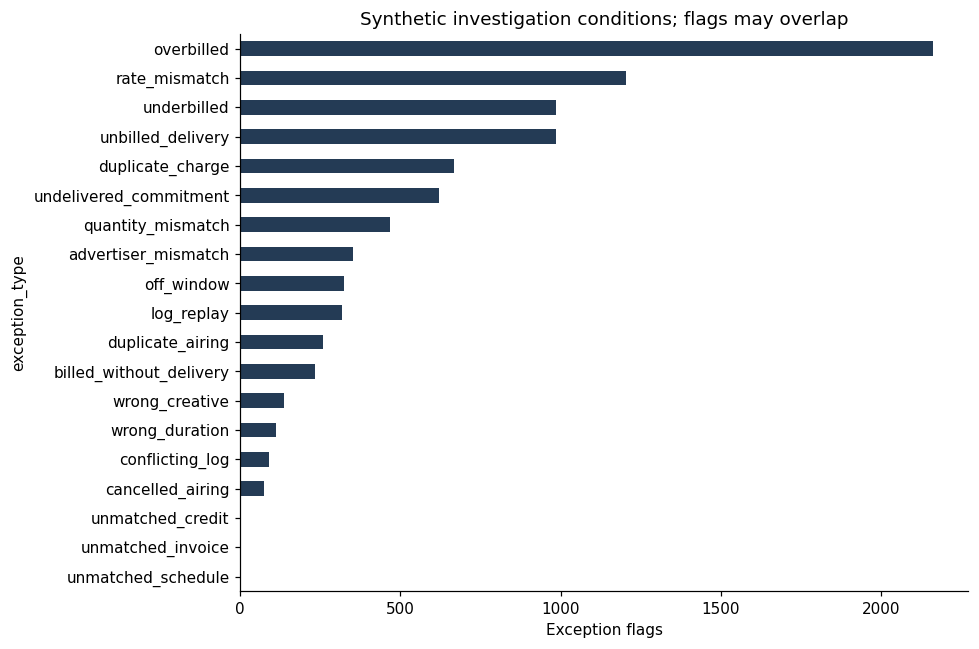

In [8]:
counts.sort_values().plot.barh(figsize=(9,6),color='#243B55')
plt.xlabel('Exception flags');plt.title('Synthetic investigation conditions; flags may overlap');plt.tight_layout();plt.show()

In [9]:
exceptions[exceptions.exception_type.str.startswith('unmatched')][['exception_type','entity_type','entity_id']].head(10)

          exception_type   entity_type    entity_id
8738    unmatched_credit        credit      K000408
8739   unmatched_invoice  invoice_line     I0016732
8740  unmatched_schedule  source_event  E-UNMATCHED

In [10]:
pd.read_csv(REPORTS/'reconciliation_controls.csv').query("unit == 'USD cents'")

                                control  source_value  ...       unit  status
5                        gross_invoices     301539914  ...  USD cents   MATCH
6                 applied_credit_amount        610500  ...  USD cents   MATCH
7  full_ledger_net_including_quarantine     300928414  ...  USD cents   MATCH
8                matched_billing_bridge     300917069  ...  USD cents   MATCH
9             expected_to_billed_bridge     300917069  ...  USD cents   MATCH

[5 rows x 6 columns]

## Billing recommendation

Review distinct commitment differences first, then inspect charge/credit details. Route payer mismatches internally and keep unmatched references separate. Unbilled eligibility is not automatically overdue because no invoice payment/due-date terms are modeled.